In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans , AgglomerativeClustering ,DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import joblib


#Load Dataset

In [4]:
df = pd.read_csv("app_user_behavior_preprocess.csv")
df.shape

(50000, 25)

In [5]:
df.isnull().sum()

user_id                          0
age                              0
gender                           0
country                          0
device_type                      0
app_version                      0
sessions_per_week                0
avg_session_duration_min         0
daily_active_minutes             0
feature_clicks_per_session       0
notifications_opened_per_week    0
in_app_search_count              0
pages_viewed_per_session         0
crash_events_last_30_days        0
support_tickets_raised           0
days_since_last_login            0
subscription_type                0
ads_clicked_last_30_days         0
content_downloads                0
social_shares                    0
rating_given                     0
churn_risk_score                 0
engagement_score                 0
account_age_days                 0
marketing_source                 0
dtype: int64

##Using standard Scaler for features selected in features selection.

In [6]:
features = ['sessions_per_week', 'avg_session_duration_min', 'daily_active_minutes',
            'feature_clicks_per_session', 'notifications_opened_per_week',
            'in_app_search_count', 'pages_viewed_per_session',
            'days_since_last_login', 'content_downloads', 'engagement_score']

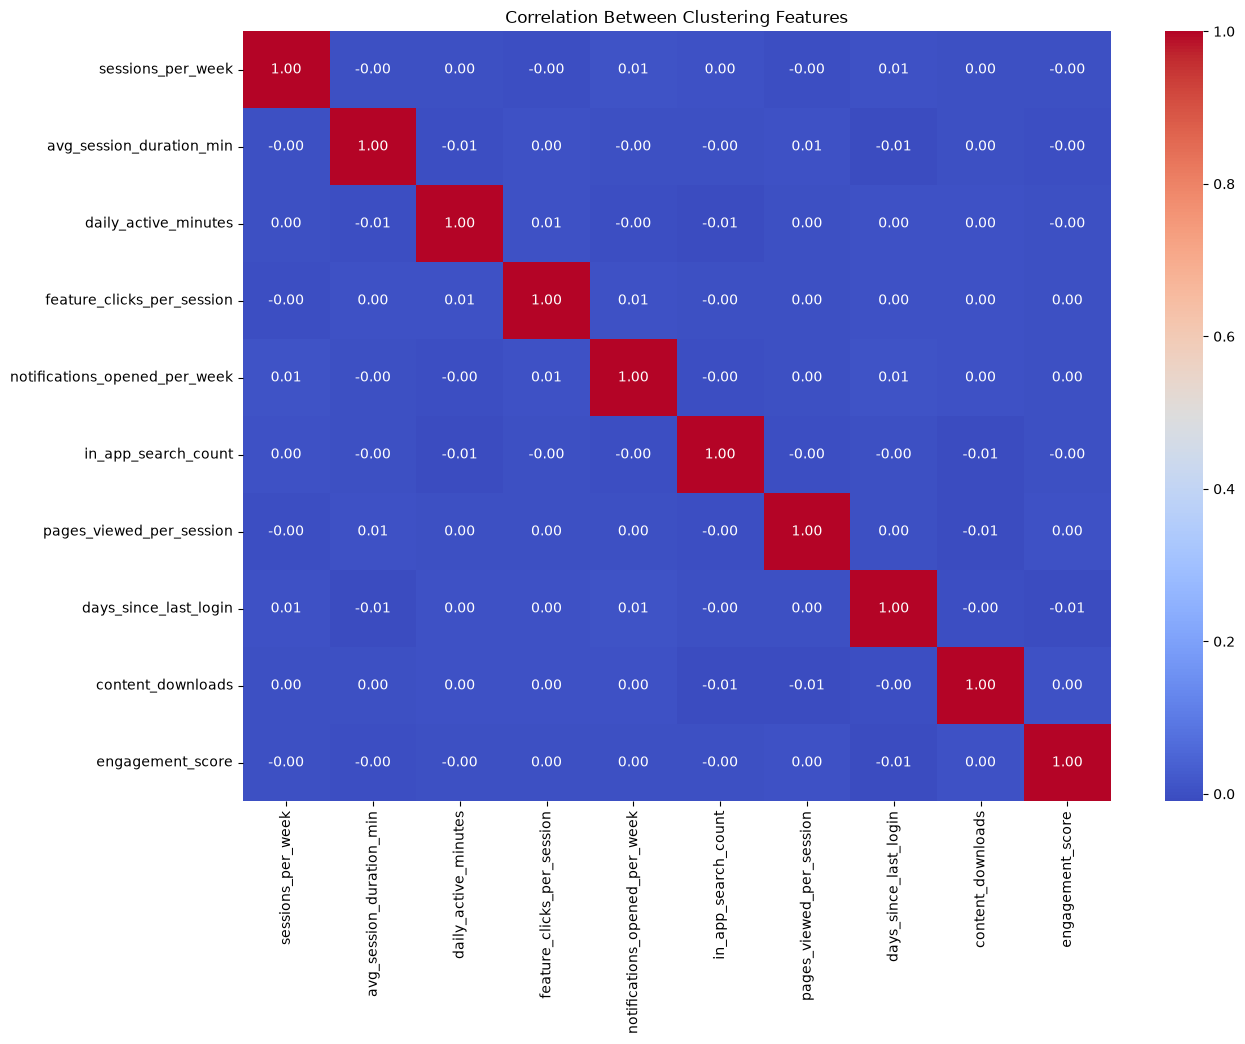

In [7]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    df[features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Clustering Features")
plt.show()

In [8]:
x = df[features]
x_scaled = StandardScaler().fit_transform(x)

In [9]:
x_scaled = pd.DataFrame(x_scaled, columns=features)

##Elbow Graph

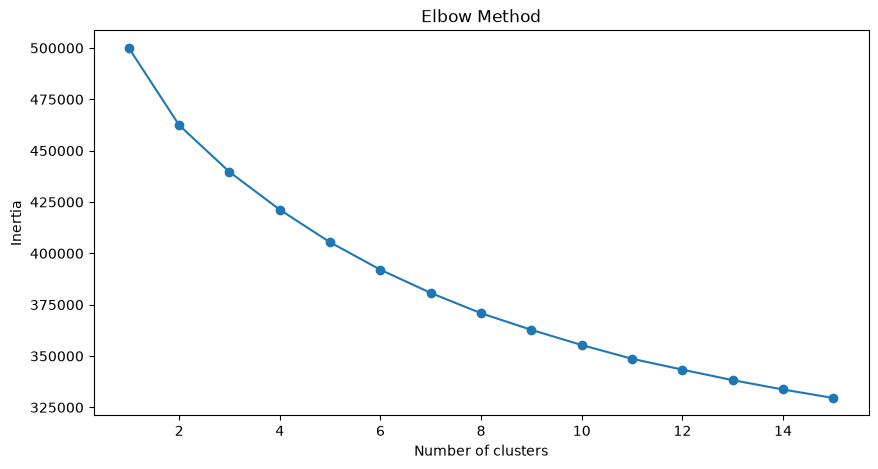

In [10]:
inertia = []
for i in range(1, 16):
    model = KMeans(n_clusters=i, random_state=42, n_init=10)
    model.fit(x_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(range(1, 16), inertia, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.show()

##K-Mens model

In [11]:
model = KMeans(n_clusters=4, random_state=42, n_init=10)
model.fit(x_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",4
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](4, 10)","[[ 0

In [12]:
pred = model.predict(x_scaled)
pred

array([2, 0, 2, ..., 0, 1, 1], shape=(50000,), dtype=int32)

In [13]:
score = silhouette_score(x_scaled, pred)
print(score)

0.06552538149131573


In [14]:

df_clustered = x_scaled.copy()
df_clustered["Cluster"] = model.predict(x_scaled)


####Cluster-Level User Identification & Profiling

In [15]:
# 1. Create a copy of your original dataframe and add the cluster labels
df_clustered = df.copy()
df_clustered["Cluster"] = pred

# 2. Now run your profiling code safely!
profile = df_clustered.groupby("Cluster").agg(
    users=("user_id", "count"),
    sessions=("sessions_per_week", "mean"),
    duration=("avg_session_duration_min", "mean"),
    engagement=("engagement_score", "mean"),
    churn_risk=("churn_risk_score", "mean"),
    last_login=("days_since_last_login", "mean"),
)
display(profile)

,users,sessions,duration,engagement,churn_risk,last_login
Cluster,,,,,,
0,10612,8.109687,-0.001987,65.696361,0.502119,22.444214
1,14421,7.978365,-0.016299,64.598723,0.498807,22.157825
2,10391,7.927533,0.019885,65.068430,0.504355,21.485709
3,14576,7.950055,0.003397,64.808466,0.499395,22.018249


In [16]:
cluster_summary = df_clustered.select_dtypes(include='number').groupby("Cluster").mean()
display(cluster_summary)

,user_id,age,app_version,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,notifications_opened_per_week,in_app_search_count,pages_viewed_per_session,crash_events_last_30_days,support_tickets_raised,days_since_last_login,ads_clicked_last_30_days,content_downloads,social_shares,rating_given,churn_risk_score,engagement_score,account_age_days
Cluster,,,,,,,,,,,,,,,,,,,,
0,124958.060592,38.556069,1.476988,8.109687,-0.001987,44.937985,0.070825,7.989917,4.014512,13.748775,-0.012416,0.007145,22.444214,5.972201,2.681210,-0.004032,0.001301,0.502119,65.696361,599.650961
1,125145.748769,38.526732,1.473539,7.978365,-0.016299,44.949326,-0.015025,4.078635,4.046391,7.429929,-0.004304,0.006559,22.157825,5.986894,2.210873,-0.002385,0.006643,0.498807,64.598723,607.019069
2,124769.064768,38.587528,1.479059,7.927533,0.019885,45.703989,-0.014428,4.609662,3.827639,12.967568,0.005423,-0.008479,21.485709,6.011548,5.386681,0.013715,-0.013824,0.504355,65.068430,603.829564
3,125049.249863,38.415066,1.475967,7.950055,0.003397,44.923455,-0.026413,3.994992,4.017083,19.603664,0.009432,-0.005647,22.018249,5.970362,2.300014,-0.004482,0.002335,0.499395,64.808466,603.563666


In [17]:
cluster_names = {
    0: "Moderate / Regular Users",
    1: "Active Time / Low Score Users",
    2: "Low Engagement / At-Risk Users",
    3: "High Engagement Users",
}
df_clustered["Cluster_Name"] = df_clustered["Cluster"].map(cluster_names)
df_clustered.shape

(50000, 27)

##PCA

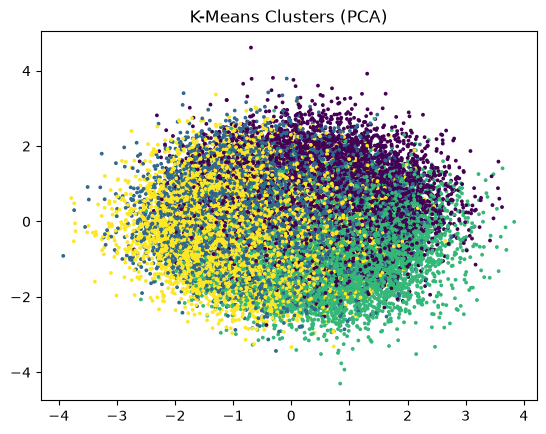

In [18]:
pcs = PCA(n_components=2, random_state=42).fit_transform(x_scaled)
plt.scatter(pcs[:, 0], pcs[:, 1], c=pred, s=3, cmap="viridis")
plt.title("K-Means Clusters (PCA)")
plt.show()

#DBSCAN

In [19]:
dbscan = DBSCAN(eps=1.5, min_samples=10)

dbscan.fit(x_scaled)

dbscan_labels = dbscan.labels_

dbscan_labels

array([-1,  0, -1, ...,  0,  0,  0], shape=(50000,))

In [20]:


unique_labels = np.unique(dbscan_labels)

print("Number of clusters:", len(unique_labels) - (1 if -1 in unique_labels else 0))
print("Noise points:", list(dbscan_labels).count(-1))

Number of clusters: 4
Noise points: 12976


In [21]:
df_dbscan = x_scaled.copy()

df_dbscan["Cluster"] = dbscan_labels

cluster_summary_dbscan = df_dbscan.groupby("Cluster").mean()

display(cluster_summary_dbscan)

,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,notifications_opened_per_week,in_app_search_count,pages_viewed_per_session,days_since_last_login,content_downloads,engagement_score
Cluster,,,,,,,,,,
-1,0.134674,-0.022888,0.018305,-0.026185,0.205009,0.190952,0.009359,-0.010055,0.271081,0.005239
0,-0.047095,0.008084,-0.006366,0.009301,-0.072226,-0.067438,-0.003166,0.003614,-0.095520,-0.001623
1,-0.787963,-0.815897,0.808754,0.050302,2.372992,1.745585,-1.209218,-0.403404,-0.698642,-0.461043
2,0.004532,-0.124018,-0.449504,-0.343225,0.067524,0.226457,-0.186810,-0.068955,2.921023,-0.984321
3,-0.235618,0.918830,-0.945244,-0.765362,0.154359,2.563576,1.029269,-0.259649,0.196544,0.431291


In [22]:
if len(set(dbscan_labels)) > 1 and len(set(dbscan_labels)) < len(dbscan_labels):

    print("Silhouette Score:", silhouette_score(x_scaled, dbscan_labels))

else:
    print("Silhouette Score cannot be calculated")

Silhouette Score: -0.07834191385535921


#Hierarchical Clustering

In [23]:
sample_scaled = x_scaled.sample(5000, random_state=42)


In [24]:
hierarchical = AgglomerativeClustering(
    n_clusters=4,
    linkage='ward'
)

hierarchical_labels = hierarchical.fit_predict(sample_scaled)

hierarchical_labels

array([3, 3, 1, ..., 2, 1, 0], shape=(5000,))

In [25]:
df_hierarchical = sample.copy()

df_hierarchical["Cluster"] = hierarchical_labels

cluster_summary_hierarchical = df_hierarchical.groupby("Cluster").mean()

display(cluster_summary_hierarchical)

NameError: name 'sample' is not defined

In [ ]:
score = silhouette_score(sample_scaled, hierarchical_labels)

print("Hierarchical Silhouette Score:", score)

Hierarchical Silhouette Score: 0.01306198019183636



#### Why K-Means was selected
The goal is to segment 50,000 users into behavioural groups without labels.
1. **Scalability** – K-Means handles 50,000 rows efficiently. Hierarchical clustering needs O(n²) memory, so it could only be run on a 5,000-row sample.
2. **Business-friendly number of segments** – K-Means lets me set k directly, giving a small set of interpretable groups. k=4 was chosen using the elbow method and silhouette scores.
3. **Suits scaled numeric data** – after StandardScaler, all features are continuous and comparable, which suits Euclidean-distance clustering.
4. **Every user gets a cluster** – DBSCAN labelled 12,976 of 50,000 users as noise and scored a negative silhouette (-0.078), so those users could not be targeted.
5. **Easy to interpret** – centroids give clear average profiles that map to business actions.

K-Means had the best silhouette (0.066) of the three methods (DBSCAN -0.078, Hierarchical 0.013).

In [ ]:

scaler = StandardScaler().fit(df[features])          # same scaler used for the model
joblib.dump(scaler, "scaler.joblib")
joblib.dump(model, "kmeans_model.joblib")            # your fitted KMeans (k=4)

df_clustered.to_csv("app_user_clustered.csv", index=False)